# Projet 2 – Notebook 2 : Représentation des données et préparation pour les modèles

**Classification de gestes de la main : comparaison de k-NN, classifieur linéaire Softmax et CNN**

Dataset : *Rock Paper Scissors* (TensorFlow Datasets) – classes : **Rock**, **Paper**, **Scissors**.

---

## 🎯 Objectif de ce notebook

Dans le Notebook 1, nous avons préparé 900 images (300 par classe), redimensionnées en 32 × 32 en RGB, puis découpées en Train / Validation / Test.

Ici, nous allons apprendre **comment présenter ces images à chacun des trois algorithmes** :

| Modèle | Forme attendue d'une image | Forme de l'ensemble Train |
|---|---|---|
| k-NN | vecteur `(3072,)` | `(540, 3072)` |
| Softmax | vecteur `(3072,)` | `(540, 3072)` |
| CNN | tenseur `(32, 32, 3)` | `(540, 32, 32, 3)` |

> ⚠️ **Ce notebook n'entraîne AUCUN modèle.** Il sert uniquement à comprendre et préparer les données.
> (Quelques petits calculs de démonstration apparaissent, mais aucun apprentissage n'a lieu.)

## 🗺️ Plan

1. Rappel et récupération des données
2. Comprendre la représentation d'une image
3. Le Flattening
4. Pourquoi le CNN est différent
5. Encodage des labels
6. Normalisation
7. Préparer les entrées des trois modèles
8. Vérifications
9. Questions de compréhension (corrigé à la toute fin)

---
# Partie 1 : Rappel et récupération des données

## 1.1 Le concept
Ce notebook doit pouvoir **s'exécuter seul**, sans le Notebook 1. Nous allons donc refaire (rapidement) la même préparation :

1. charger le dataset complet (2 892 images) ;
2. redimensionner chaque image en **32 × 32** RGB ;
3. choisir **exactement 300 images par classe** (900 au total) ;
4. faire un découpage **stratifié 60 % / 20 % / 20 %**.

## 1.2 Pourquoi en avons-nous besoin ?
Pour pouvoir comparer équitablement les trois modèles, ils doivent tous utiliser **exactement les mêmes images** dans Train, Validation et Test. On fixe donc une **graine aléatoire** (`SEED = 42`) : chaque exécution donnera le même résultat.

## 1.3 Deux mots importants
- **Reproductibilité** : relancer le code donne toujours les mêmes résultats.
- **Stratifié** : chaque partition contient les classes dans les mêmes proportions (ici 1/3, 1/3, 1/3).

> 📝 Remarque : le tirage des 300 images est fait avec la graine 42, selon la procédure ci-dessous. Si tu veux **exactement** les mêmes images que dans ton Notebook 1 et que tu as sauvegardé ses tableaux, tu peux remplacer les cellules 1.5 et 1.6 par leur chargement. Les consignes (300/classe, 32×32×3, 60/20/20) restent identiques.

In [1]:
# 1.4 Importation des bibliothèques
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split

# Graine aléatoire : garantit des résultats identiques à chaque exécution
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Paramètres imposés par le projet
N_PER_CLASS = 300     # 300 images par classe
IMG_SIZE = 32         # images 32 x 32
N_CLASSES = 3         # Rock, Paper, Scissors

print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)

TensorFlow : 2.21.0
NumPy      : 2.5.4


In [2]:
# 1.5 Chargement du dataset complet et redimensionnement en 32 x 32 RGB
# 'train+test' regroupe les deux parties officielles du dataset (2 520 + 372 = 2 892 images)
ds, info = tfds.load("rock_paper_scissors", split="train+test",
                     as_supervised=True, with_info=True, shuffle_files=False)

class_names = info.features["label"].names      # ['rock', 'paper', 'scissors']
print("Classes :", class_names)

def resize_to_uint8(img):
    # Redimensionne en 32x32 (interpolation bilinéaire avec anti-crénelage),
    # puis arrondit pour revenir à des entiers 0..255
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), antialias=True)
    img = tf.clip_by_value(img, 0, 255)
    return tf.cast(tf.round(img), tf.uint8)

ds_small = ds.map(lambda img, lab: (resize_to_uint8(img), lab),
                  num_parallel_calls=tf.data.AUTOTUNE)

imgs, labs = [], []
for img, lab in tfds.as_numpy(ds_small):
    imgs.append(img)
    labs.append(lab)

all_images = np.stack(imgs)          # (2892, 32, 32, 3), entiers 0..255
all_labels = np.array(labs)          # (2892,)
print("Dataset complet :", all_images.shape, all_labels.shape)
print("Images par classe (dataset complet) :", np.bincount(all_labels))

Classes : ['rock', 'paper', 'scissors']


I0000 00:00:1793443802.211270 5673750 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


Dataset complet : (2892, 32, 32, 3) (2892,)
Images par classe (dataset complet) : [964 964 964]


In [3]:
# 1.6 Sélection de EXACTEMENT 300 images par classe, puis split stratifié 60/20/20
rng = np.random.default_rng(SEED)          # générateur aléatoire reproductible

selected = []
for c in range(N_CLASSES):
    idx_c = np.where(all_labels == c)[0]                    # indices des images de la classe c
    selected.append(rng.choice(idx_c, size=N_PER_CLASS, replace=False))
selected = np.concatenate(selected)

X_all_raw = all_images[selected]           # (900, 32, 32, 3), valeurs 0..255 (uint8)
y_all = all_labels[selected]               # (900,)

# Étape 1 : on met 20 % de côté pour le Test
# Étape 2 : sur les 80 % restants, on prend 25 % pour la Validation (0.25 * 0.80 = 0.20)
idx = np.arange(len(y_all))
idx_trainval, idx_test = train_test_split(idx, test_size=0.20,
                                          stratify=y_all, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.25,
                                      stratify=y_all[idx_trainval], random_state=SEED)

# Versions "brutes" : entiers de 0 à 255
X_train_raw, X_val_raw, X_test_raw = X_all_raw[idx_train], X_all_raw[idx_val], X_all_raw[idx_test]
# Labels entiers
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]

# Versions normalisées (0 à 1) : la normalisation est expliquée en détail en Partie 6.
X_train = X_train_raw.astype("float32") / 255.0
X_val = X_val_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

In [4]:
# 1.7 Vérification des dimensions et de la stratification
print("X_train :", X_train.shape, "| y_train :", y_train.shape)
print("X_val   :", X_val.shape,   "| y_val   :", y_val.shape)
print("X_test  :", X_test.shape,  "| y_test  :", y_test.shape)

print("\nRépartition par classe (rock, paper, scissors) :")
for nom, y in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"  {nom:5s} -> {np.bincount(y, minlength=N_CLASSES)}  (total {len(y)})")

assert X_train.shape == (540, 32, 32, 3)
assert X_val.shape == (180, 32, 32, 3)
assert X_test.shape == (180, 32, 32, 3)
print("\n✅ Dimensions conformes au projet : 540 / 180 / 180 images de forme (32, 32, 3).")

X_train : (540, 32, 32, 3) | y_train : (540,)
X_val   : (180, 32, 32, 3) | y_val   : (180,)
X_test  : (180, 32, 32, 3) | y_test  : (180,)

Répartition par classe (rock, paper, scissors) :
  Train -> [180 180 180]  (total 540)
  Val   -> [60 60 60]  (total 180)
  Test  -> [60 60 60]  (total 180)

✅ Dimensions conformes au projet : 540 / 180 / 180 images de forme (32, 32, 3).


### 🔍 Interprétation
- `(540, 32, 32, 3)` se lit : **540 images**, chacune de **32 lignes × 32 colonnes × 3 canaux**.
- Chaque ensemble contient **autant d'images de chaque classe** : Train = 180 + 180 + 180 (rock, paper, scissors), Val = 60 + 60 + 60, Test = 60 + 60 + 60.
- Le split est **stratifié** : aucune classe n'est favorisée.

---
# Partie 2 : Comprendre la représentation d'une image

## 2.1 Le concept
Pour un ordinateur, une image n'est **pas un dessin** : c'est un **tableau de nombres**.

Une image RGB de 32 × 32 est un tableau NumPy de forme `(32, 32, 3)` :
- **32** = nombre de lignes de pixels (hauteur) ;
- **32** = nombre de colonnes de pixels (largeur) ;
- **3** = nombre de **canaux de couleur** : **R**ouge, **G**reen (vert), **B**leu.

Chaque pixel est donc décrit par **3 nombres** : l'intensité de rouge, de vert et de bleu.
Par exemple `(255, 0, 0)` = rouge pur, `(0, 0, 0)` = noir, `(255, 255, 255)` = blanc.

## 2.2 Pourquoi en avons-nous besoin ?
Tous les modèles de ML travaillent sur des nombres. Comprendre exactement **où se trouvent les nombres** dans le tableau est indispensable pour savoir ensuite comment les réorganiser (Flattening) ou les conserver (CNN).

## 2.3 Une image versus un ensemble d'images
| Objet | Forme | Signification |
|---|---|---|
| Une image | `(32, 32, 3)` | hauteur, largeur, canaux |
| Un ensemble de N images | `(N, 32, 32, 3)` | **N** images empilées ; le premier axe est l'index de l'image |

Le premier axe (N) est souvent appelé la **dimension du lot** ou *batch*.

## 2.4 Nombre de valeurs d'une image
$$32 \times 32 \times 3 = 3\,072 \text{ valeurs}$$

In [5]:
# 2.5 Une image, ses dimensions et son nombre de valeurs
img = X_train[0]
print("Forme d'UNE image        :", img.shape)
print("Forme de l'ENSEMBLE      :", X_train.shape)
print("Nombre de valeurs / image:", img.size, "=", " x ".join(map(str, img.shape)))
print("Valeurs totales (Train)  :", X_train.size, "=", X_train.shape[0], "x", img.size)
print("Type des valeurs         :", img.dtype)
print("Classe de cette image    :", y_train[0], "->", class_names[y_train[0]])

# Le pixel en haut à gauche : 3 nombres (R, G, B) en version brute 0..255
print("\nPixel (0,0) brut  [R, G, B] :", X_train_raw[0, 0, 0])
print("Pixel (0,0) normalisé       :", X_train[0, 0, 0])

Forme d'UNE image        : (32, 32, 3)
Forme de l'ENSEMBLE      : (540, 32, 32, 3)
Nombre de valeurs / image: 3072 = 32 x 32 x 3
Valeurs totales (Train)  : 1658880 = 540 x 3072
Type des valeurs         : float32
Classe de cette image    : 0 -> rock

Pixel (0,0) brut  [R, G, B] : [254 254 254]
Pixel (0,0) normalisé       : [0.99607843 0.99607843 0.99607843]


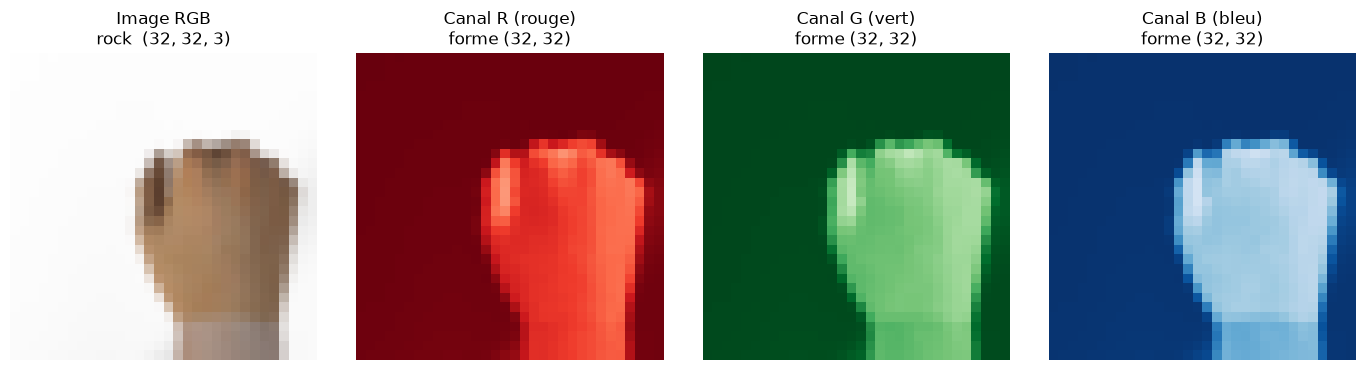

In [6]:
# 2.6 Visualisation : l'image et ses trois canaux R, G, B
img = X_train[0]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))

axes[0].imshow(img)
axes[0].set_title(f"Image RGB\n{class_names[y_train[0]]}  {img.shape}")

for k, (nom, cmap) in enumerate(zip(["R (rouge)", "G (vert)", "B (bleu)"],
                                    ["Reds", "Greens", "Blues"])):
    axes[k + 1].imshow(img[:, :, k], cmap=cmap, vmin=0, vmax=1)
    axes[k + 1].set_title(f"Canal {nom}\nforme {img[:, :, k].shape}")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

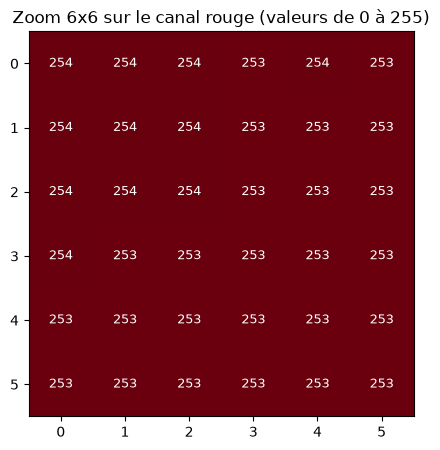

In [7]:
# 2.7 Zoom : une petite zone 6x6 du canal rouge avec les valeurs numériques brutes (0..255)
patch = X_train_raw[0, :6, :6, 0]
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(patch, cmap="Reds", vmin=0, vmax=255)
for i in range(6):
    for j in range(6):
        ax.text(j, i, str(patch[i, j]), ha="center", va="center", fontsize=9,
                color="white" if patch[i, j] > 160 else "black")
ax.set_title("Zoom 6x6 sur le canal rouge (valeurs de 0 à 255)")
ax.set_xticks(range(6)); ax.set_yticks(range(6))
plt.show()

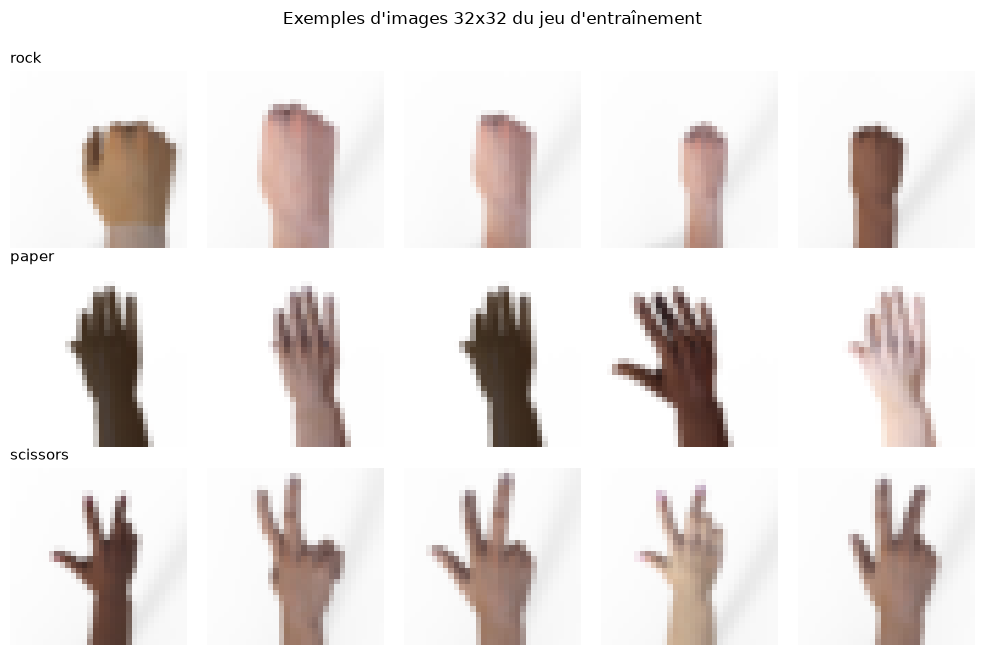

In [8]:
# 2.8 Quelques exemples de chaque classe
fig, axes = plt.subplots(N_CLASSES, 5, figsize=(10, 6.5))
for c in range(N_CLASSES):
    exemples = np.where(y_train == c)[0][:5]
    for j, i in enumerate(exemples):
        axes[c, j].imshow(X_train[i])
        axes[c, j].axis("off")
        if j == 0:
            axes[c, j].set_title(class_names[c], loc="left", fontsize=11)
plt.suptitle("Exemples d'images 32x32 du jeu d'entraînement", y=1.0)
plt.tight_layout()
plt.show()

### 🔍 Interprétation
- Une image est bien un tableau `(32, 32, 3)` contenant **3 072 nombres**.
- Chaque canal est lui-même une petite image en niveaux d'intensité `(32, 32)`.
- `X_train` empile 540 de ces images : `(540, 32, 32, 3)` soit 1 658 880 nombres au total.
- À 32 × 32, les images sont floues, mais la forme générale de la main reste visible : c'est une contrainte volontaire du projet.

---
# Partie 3 : Le Flattening (aplatissement)

## 3.1 Qu'est-ce que le Flattening ?
**Flattening** = « aplatir ». On prend le tableau 3D `(32, 32, 3)` et on **met tous ses nombres à la suite, dans une seule ligne** : un **vecteur** de forme `(3072,)`.

```
Image (32, 32, 3)                      Vecteur (3072,)
[ [[r,g,b], [r,g,b], ...],     ->      [r, g, b, r, g, b, r, g, b, ..., b]
  [[r,g,b], [r,g,b], ...],
  ... ]
```

L'ordre suivi par NumPy (« ordre C ») est : on parcourt la **première ligne de pixels de gauche à droite** (en prenant R, G, B pour chaque pixel), puis la deuxième ligne, etc.

L'index d'une valeur dans le vecteur est : `index = ligne × (32×3) + colonne × 3 + canal`.

## 3.2 Pourquoi transformer `(32, 32, 3)` en `(3072,)` ?
Les algorithmes k-NN et Softmax **attendent une ligne de nombres par exemple** :
- **k-NN** calcule une **distance** entre deux vecteurs ;
- **Softmax** calcule des **scores linéaires** : `score = W · x + b`, un produit de matrice par un vecteur.

Pour ces deux modèles, un jeu de données est donc un **tableau 2D** `(N, D)` : N exemples (lignes), D caractéristiques (colonnes). Ici D = 3072.

## 3.3 Avec NumPy
```python
x_flat = x.reshape(-1)                         # une image   : (32,32,3)   -> (3072,)
X_flat = X.reshape(X.shape[0], -1)             # un ensemble : (540,32,32,3) -> (540,3072)
```
Le `-1` signifie : « NumPy, calcule toi-même la taille manquante ». Ici : 32×32×3 = 3072.

## 3.4 Pourquoi cette représentation convient à k-NN et Softmax ?
- k-NN : la distance euclidienne entre deux images aplaties compare **pixel par pixel** (même position, même canal). Ce calcul n'a pas besoin de savoir qui est voisin de qui.
- Softmax : chaque pixel reçoit son **propre poids** dans la matrice `W` de taille `(3, 3072)`. Là encore, la position 2D n'est pas utilisée dans le calcul.

## 3.5 Perdre les valeurs ≠ perdre la structure spatiale explicite
C'est un point subtil mais **essentiel** :

- **Les valeurs des pixels ne sont PAS perdues.** Le Flattening est une simple réorganisation : on peut revenir à l'image d'origine avec le `reshape` inverse (nous le prouverons plus bas).
- Ce qui disparaît, c'est la **structure spatiale explicite** : dans le tableau `(32, 32, 3)` on *voit* qu'un pixel a un voisin au-dessus, en dessous, à gauche, à droite. Dans le vecteur `(3072,)`, cette information « voisinage » n'est plus visible directement : deux pixels voisins verticalement se retrouvent à **96 positions** l'un de l'autre.
- Et surtout : **k-NN et Softmax ne l'utilisent pas** de toute façon. Seul le CNN sait en tirer profit (Partie 4).

In [9]:
# 3.6 Exemple 1 : aplatir UNE image
x = X_train[0]                    # (32, 32, 3)
x_flat = x.reshape(-1)            # (3072,)

print("Avant :", x.shape)
print("Après :", x_flat.shape)

# L'ordre des valeurs : pixel (0,0) -> R,G,B, puis pixel (0,1) -> R,G,B, ...
print("\n9 premières valeurs du vecteur :", np.round(x_flat[:9], 3))
print("Pixel (0,0) =", np.round(x[0, 0], 3), "| pixel (0,1) =", np.round(x[0, 1], 3),
      "| pixel (0,2) =", np.round(x[0, 2], 3))

# Vérification de la formule d'index : index = ligne*96 + colonne*3 + canal
ligne, colonne, canal = 5, 7, 1
index = ligne * (32 * 3) + colonne * 3 + canal
print(f"\nValeur x[{ligne},{colonne},{canal}] = {x[ligne, colonne, canal]:.4f}")
print(f"Valeur x_flat[{index}]   = {x_flat[index]:.4f}")
assert x[ligne, colonne, canal] == x_flat[index]

Avant : (32, 32, 3)
Après : (3072,)

9 premières valeurs du vecteur : [0.996 0.996 0.996 0.996 0.996 0.996 0.996 0.996 0.996]
Pixel (0,0) = [0.996 0.996 0.996] | pixel (0,1) = [0.996 0.996 0.996] | pixel (0,2) = [0.996 0.996 0.996]

Valeur x[5,7,1] = 0.9922
Valeur x_flat[502]   = 0.9922


In [10]:
# 3.7 Exemple 2 : aplatir TOUT l'ensemble d'images
X_train_flat_demo = X_train.reshape(X_train.shape[0], -1)
print("Avant :", X_train.shape)
print("Après :", X_train_flat_demo.shape)
print("→ 540 lignes (une par image) et 3072 colonnes (une par valeur de pixel)")

# Le nombre d'images n'a pas changé, le nombre total de valeurs non plus :
assert X_train.size == X_train_flat_demo.size

Avant : (540, 32, 32, 3)
Après : (540, 3072)
→ 540 lignes (une par image) et 3072 colonnes (une par valeur de pixel)


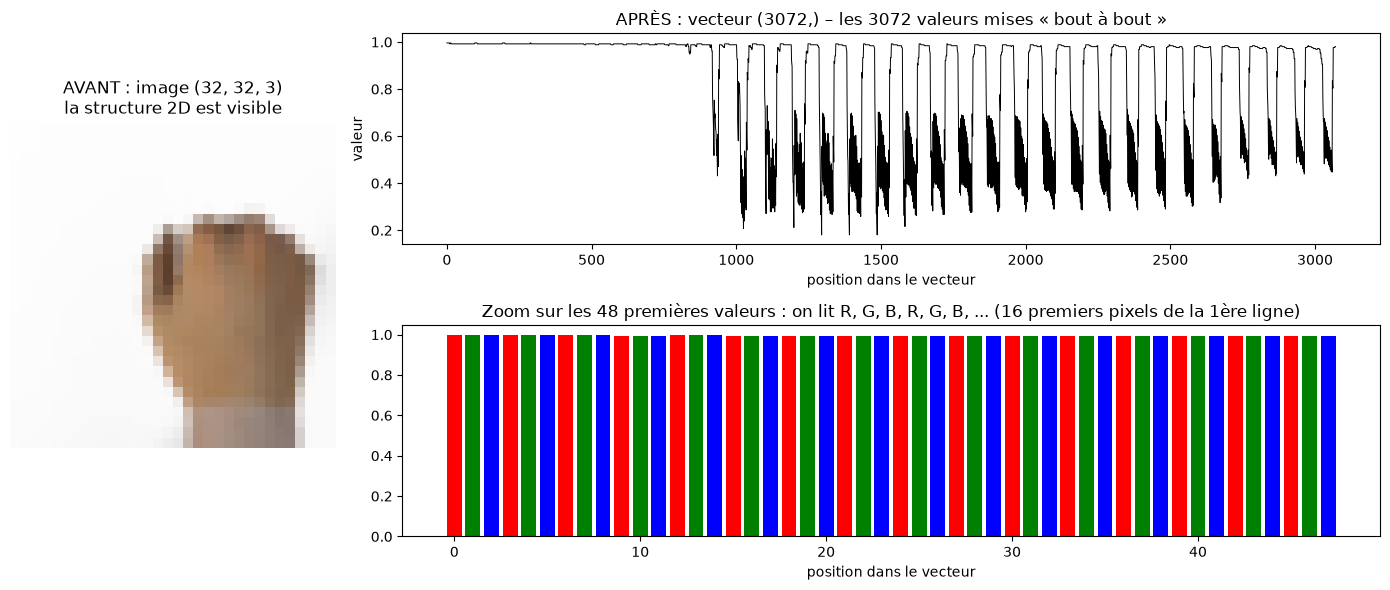

In [11]:
# 3.8 Visualisation avant / après
x = X_train[0]
x_flat = x.reshape(-1)

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 3])

ax0 = fig.add_subplot(gs[:, 0])
ax0.imshow(x)
ax0.set_title("AVANT : image (32, 32, 3)\nla structure 2D est visible")
ax0.axis("off")

ax1 = fig.add_subplot(gs[0, 1])
ax1.plot(x_flat, linewidth=0.7, color="black")
ax1.set_title("APRÈS : vecteur (3072,) – les 3072 valeurs mises « bout à bout »")
ax1.set_xlabel("position dans le vecteur"); ax1.set_ylabel("valeur")

ax2 = fig.add_subplot(gs[1, 1])
zone = x_flat[:48]
couleurs = ["red", "green", "blue"] * 16     # R, G, B qui se répètent
ax2.bar(range(48), zone, color=couleurs)
ax2.set_title("Zoom sur les 48 premières valeurs : on lit R, G, B, R, G, B, ... (16 premiers pixels de la 1ère ligne)")
ax2.set_xlabel("position dans le vecteur")
plt.tight_layout()
plt.show()

Forme reconstruite : (32, 32, 3)
Image identique à l'originale ? True
Ensemble reconstruit : (540, 32, 32, 3) | identique ? True


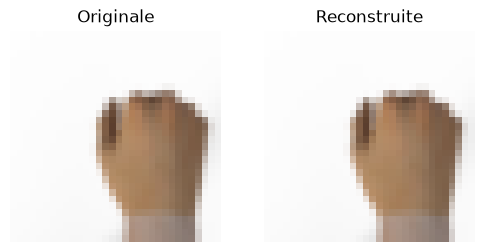

In [12]:
# 3.9 Reconstruction : le reshape inverse prouve que les valeurs sont conservées
x_flat = X_train[0].reshape(-1)               # (3072,)
x_reconstruit = x_flat.reshape(32, 32, 3)     # on revient à (32, 32, 3)

print("Forme reconstruite :", x_reconstruit.shape)
print("Image identique à l'originale ?", np.array_equal(X_train[0], x_reconstruit))

# Même chose pour tout l'ensemble
X_train_flat_demo = X_train.reshape(X_train.shape[0], -1)
X_train_reconstruit = X_train_flat_demo.reshape(-1, 32, 32, 3)
print("Ensemble reconstruit :", X_train_reconstruit.shape,
      "| identique ?", np.array_equal(X_train, X_train_reconstruit))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(X_train[0]); axes[0].set_title("Originale")
axes[1].imshow(x_reconstruit); axes[1].set_title("Reconstruite")
for ax in axes: ax.axis("off")
plt.show()

Distance euclidienne (vecteurs originaux) : 14.186100
Distance euclidienne (colonnes mélangées) : 14.186099
Égales ? True


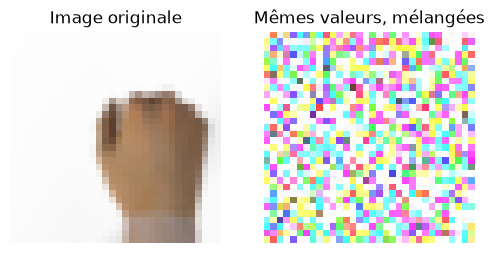

In [13]:
# 3.10 Démonstration : k-NN ne « voit » pas la structure spatiale
# On mélange les 3072 colonnes avec UNE MÊME permutation pour toutes les images.
# L'image devient méconnaissable pour un humain... mais les distances entre images
# sont EXACTEMENT les mêmes : un k-NN donnerait donc exactement les mêmes voisins.
rng_demo = np.random.default_rng(SEED)
perm = rng_demo.permutation(3072)

a, b = X_train[0].reshape(-1), X_train[1].reshape(-1)
dist_originale = np.linalg.norm(a - b)
dist_melangee = np.linalg.norm(a[perm] - b[perm])
print(f"Distance euclidienne (vecteurs originaux) : {dist_originale:.6f}")
print(f"Distance euclidienne (colonnes mélangées) : {dist_melangee:.6f}")
print("Égales ?", np.isclose(dist_originale, dist_melangee))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(a.reshape(32, 32, 3)); axes[0].set_title("Image originale")
axes[1].imshow(a[perm].reshape(32, 32, 3)); axes[1].set_title("Mêmes valeurs, mélangées")
for ax in axes: ax.axis("off")
plt.show()

### 🔍 Interprétation
- `reshape(-1)` ne change **aucune valeur**, seulement leur organisation. La reconstruction est **strictement identique** (`np.array_equal` → `True`).
- La démonstration 3.10 est parlante : si on mélange les pixels de la même façon pour toutes les images, la distance entre deux images ne change pas. k-NN (qui repose sur la distance) **ne bénéficie donc pas de l'organisation spatiale** : l'aplatissement ne lui fait rien perdre d'utilisable.
- Pour un CNN, ce mélange serait catastrophique, car il détruirait les voisinages. C'est l'objet de la partie suivante.

---
# Partie 4 : Comprendre pourquoi le CNN est différent

## 4.1 Le concept
**CNN** = *Convolutional Neural Network* (réseau de neurones convolutif). Contrairement à k-NN et Softmax, il **garde la forme `(32, 32, 3)`** : il travaille directement sur l'image en 2D.

## 4.2 Pourquoi ?
Dans une image, **les pixels voisins sont liés**. Un contour, un doigt, une courbe sont formés par des groupes de pixels proches. Pour reconnaître un geste (poing fermé, main ouverte, deux doigts), la **forme locale** compte beaucoup.

## 4.3 Le principe de la convolution
Une **convolution** fait glisser une petite fenêtre (un **filtre** ou *kernel*, par exemple 3 × 3) sur l'image :

1. on place le filtre sur un petit voisinage de 3 × 3 pixels ;
2. on multiplie chaque pixel par le poids correspondant du filtre, puis on additionne : cela donne **un seul nombre** ;
3. on décale le filtre d'un cran et on recommence ;
4. tous les résultats forment une nouvelle image appelée **carte de caractéristiques** (*feature map*).

Un filtre bien choisi détecte quelque chose de précis : un contour vertical, un contour horizontal, une tache claire, etc. Dans un CNN, **les filtres ne sont pas écrits à la main : ils sont appris** pendant l'entraînement (ce que nous ne faisons pas ici).

## 4.4 Représentation aplatie vs spatiale

| | Aplatie `(3072,)` | Spatiale `(32, 32, 3)` |
|---|---|---|
| Voisinage des pixels | non explicite | **conservé** |
| Modèles | k-NN, Softmax | **CNN** |
| Un pixel et son voisin du dessous | séparés de 96 positions | adjacents dans le tableau |
| Nombre de poids par neurone | 3 072 (un par pixel) | 27 par filtre 3×3×3 (partagés partout) |

Un point clé : **le filtre est réutilisé sur toute l'image** (partage de poids). Un même détecteur de contour fonctionne à gauche comme à droite.

In [14]:
# 4.5 Une convolution « à la main » avec NumPy (démonstration, aucun apprentissage)
gris = X_train[0].mean(axis=2)                 # image en niveaux de gris (32, 32) pour simplifier

# Filtre 3x3 qui détecte les contours VERTICAUX (filtre de Sobel)
filtre = np.array([[-1, 0, 1],
                   [-2, 0, 2],
                   [-1, 0, 1]], dtype=float)

def convolution_simple(image, kernel):
    # Fait glisser le filtre sur l'image (sans bordure ajoutée)
    h, w = image.shape
    kh, kw = kernel.shape
    sortie = np.zeros((h - kh + 1, w - kw + 1))
    for i in range(sortie.shape[0]):
        for j in range(sortie.shape[1]):
            voisinage = image[i:i + kh, j:j + kw]        # petite fenêtre 3x3
            sortie[i, j] = np.sum(voisinage * kernel)    # multiplier puis additionner
    return sortie

carte = convolution_simple(gris, filtre)
print("Image en gris :", gris.shape, "-> carte de caractéristiques :", carte.shape)
print("(32 - 3 + 1 = 30 : le filtre ne peut pas déborder de l'image)")

Image en gris : (32, 32) -> carte de caractéristiques : (30, 30)
(32 - 3 + 1 = 30 : le filtre ne peut pas déborder de l'image)


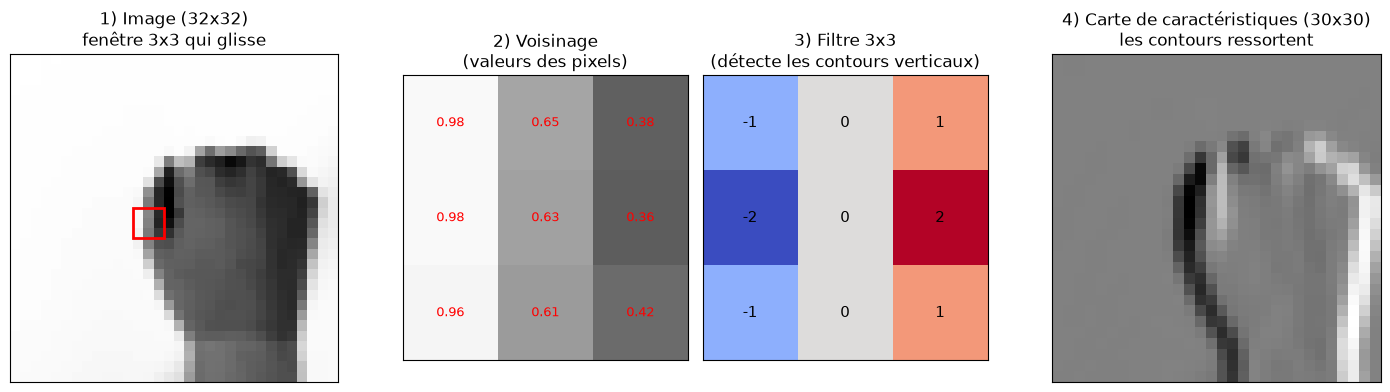

In [15]:
# 4.6 Schéma pédagogique : image -> filtre qui glisse -> carte de caractéristiques
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 4, figsize=(15, 4), gridspec_kw={"width_ratios": [1.2, 0.8, 0.8, 1.2]})

# (a) image avec une fenêtre 3x3 surlignée
axes[0].imshow(gris, cmap="gray")
axes[0].add_patch(Rectangle((11.5, 14.5), 3, 3, fill=False, edgecolor="red", linewidth=2))
axes[0].set_title("1) Image (32x32)\nfenêtre 3x3 qui glisse")

# (b) zoom sur le voisinage
voisinage = gris[15:18, 12:15]
axes[1].imshow(voisinage, cmap="gray", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, f"{voisinage[i, j]:.2f}", ha="center", va="center", color="red", fontsize=9)
axes[1].set_title("2) Voisinage\n(valeurs des pixels)")

# (c) le filtre
axes[2].imshow(filtre, cmap="coolwarm")
for i in range(3):
    for j in range(3):
        axes[2].text(j, i, f"{filtre[i, j]:.0f}", ha="center", va="center", fontsize=11)
axes[2].set_title("3) Filtre 3x3\n(détecte les contours verticaux)")

# (d) résultat
axes[3].imshow(carte, cmap="gray")
axes[3].set_title("4) Carte de caractéristiques (30x30)\nles contours ressortent")

for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [16]:
# 4.7 Pourquoi l'aplatissement « cache » le voisinage : distance entre deux pixels voisins
ligne, colonne, canal = 10, 10, 0
idx_pixel = ligne * 96 + colonne * 3 + canal
idx_voisin_droite = ligne * 96 + (colonne + 1) * 3 + canal
idx_voisin_dessous = (ligne + 1) * 96 + colonne * 3 + canal

print("Dans l'image 2D, le pixel (10,10) et ses voisins (10,11) et (11,10) sont collés.")
print(f"Dans le vecteur aplati : positions {idx_pixel}, {idx_voisin_droite}, {idx_voisin_dessous}")
print(f"  écart avec le voisin de droite  : {idx_voisin_droite - idx_pixel} positions")
print(f"  écart avec le voisin du dessous : {idx_voisin_dessous - idx_pixel} positions")

Dans l'image 2D, le pixel (10,10) et ses voisins (10,11) et (11,10) sont collés.
Dans le vecteur aplati : positions 990, 993, 1086
  écart avec le voisin de droite  : 3 positions
  écart avec le voisin du dessous : 96 positions


In [17]:
# 4.8 Un CNN accepte directement la forme (32, 32, 3) – simple passage en avant, SANS entraînement
# On crée une seule couche de convolution avec 8 filtres 3x3 (poids aléatoires, non appris).
couche = tf.keras.layers.Conv2D(filters=8, kernel_size=(3, 3), activation="relu")
sortie = couche(X_train[:1])           # on lui donne 1 image : forme (1, 32, 32, 3)

print("Entrée  :", X_train[:1].shape)
print("Sortie  :", sortie.shape, "-> 8 cartes de caractéristiques de taille 30x30")

# Nombre de paramètres : 3 x 3 x 3 (canaux) x 8 filtres + 8 biais
print("Paramètres de cette couche :", couche.count_params(), "= 3*3*3*8 + 8 =", 3 * 3 * 3 * 8 + 8)

Entrée  : (1, 32, 32, 3)
Sortie  : (1, 30, 30, 8) -> 8 cartes de caractéristiques de taille 30x30
Paramètres de cette couche : 224 = 3*3*3*8 + 8 = 224


### 🔍 Interprétation
- Un filtre 3×3 regarde **9 pixels voisins à la fois** (27 valeurs avec les 3 canaux). C'est le **voisinage** qui lui donne du sens.
- Dans le vecteur aplati, deux pixels voisins verticalement sont séparés de 96 positions : un modèle qui lit le vecteur ne sait pas qu'ils sont voisins.
- La couche convolutive n'a besoin que de **224 paramètres** pour traiter l'image entière, car elle réutilise les mêmes 8 filtres partout.
- ⚠️ Ici, aucun entraînement n'a eu lieu : les poids du filtre sont aléatoires. On a seulement vérifié que la **forme `(32, 32, 3)` est bien celle attendue par le CNN**.

---
# Partie 5 : Encodage des labels

## 5.1 Labels entiers
Nos classes sont stockées sous forme d'entiers :

| Entier | Classe |
|---|---|
| 0 | rock |
| 1 | paper |
| 2 | scissors |

Un label entier est compact : `y_train` est un vecteur de forme `(540,)`.

## 5.2 One-Hot Encoding
Le **One-Hot Encoding** remplace chaque entier par un vecteur de longueur égale au nombre de classes, avec un **1** à la position de la classe et des **0** ailleurs :

| Classe | Entier | One-Hot |
|---|---|---|
| rock | 0 | `[1, 0, 0]` |
| paper | 1 | `[0, 1, 0]` |
| scissors | 2 | `[0, 0, 1]` |

`y_train` passe alors de `(540,)` à `(540, 3)`.

## 5.3 Pourquoi deux représentations ?
- Un entier peut laisser croire qu'il existe un **ordre** (« scissors = 2 est plus grand que rock = 0 ») qui n'a aucun sens ici. Le One-Hot traite toutes les classes de façon égale.
- Un réseau avec une sortie Softmax produit **3 probabilités** `[p_rock, p_paper, p_scissors]` : le One-Hot a exactement la même forme, ce qui permet de les comparer directement.

## 5.4 Les deux fonctions de perte (à connaître pour le CNN)
La **perte** (*loss*) mesure l'erreur du modèle. Mathématiquement, c'est la même formule : $-\log(p_{\text{classe correcte}})$. La différence porte uniquement sur le **format des labels** attendus :

| Fonction | Labels attendus | Exemple pour « paper » |
|---|---|---|
| `sparse_categorical_crossentropy` | entiers | `1` |
| `categorical_crossentropy` | One-Hot | `[0, 1, 0]` |

Règle simple : **labels entiers → `sparse_...` ; labels One-Hot → `categorical_...`**. Se tromper de format provoque une erreur ou de mauvais résultats.

## 5.5 `tf.keras.utils.to_categorical`
Cette fonction transforme des labels entiers en One-Hot : `to_categorical(y, num_classes=3)`.

In [18]:
# 5.6 Exemple avec trois classes
y_exemple = np.array([0, 1, 2, 1, 0])
y_exemple_oh = tf.keras.utils.to_categorical(y_exemple, num_classes=3)

print("Labels entiers :", y_exemple, "forme", y_exemple.shape)
print("One-Hot :\n", y_exemple_oh, "\nforme", y_exemple_oh.shape)

# Même résultat avec NumPy pur : on prend les lignes de la matrice identité
print("\nAvec np.eye(3)[y] :\n", np.eye(3)[y_exemple])

# Retour au label entier : l'indice du 1 -> argmax
print("\nRetour avec argmax :", np.argmax(y_exemple_oh, axis=1))

Labels entiers : [0 1 2 1 0] forme (5,)
One-Hot :
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]] 
forme (5, 3)

Avec np.eye(3)[y] :
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]

Retour avec argmax : [0 1 2 1 0]


In [19]:
# 5.7 Application à nos ensembles
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=N_CLASSES)
y_val_oh = tf.keras.utils.to_categorical(y_val, num_classes=N_CLASSES)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes=N_CLASSES)

print("y_train    :", y_train.shape, "  -> premiers labels :", y_train[:6])
print("y_train_oh :", y_train_oh.shape, "-> premières lignes :\n", y_train_oh[:6])

assert np.array_equal(np.argmax(y_train_oh, axis=1), y_train)
print("\n✅ argmax(One-Hot) redonne exactement les labels entiers.")

y_train    : (540,)   -> premiers labels : [0 2 1 0 0 2]
y_train_oh : (540, 3) -> premières lignes :
 [[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 0. 1.]]

✅ argmax(One-Hot) redonne exactement les labels entiers.


In [20]:
# 5.8 Les deux fonctions de perte donnent le même résultat (avec le bon format de labels)
# Ce sont de simples calculs sur des prédictions INVENTÉES : aucun modèle n'est entraîné.
y_vrai_entier = np.array([0, 1, 2])
y_vrai_oh = tf.keras.utils.to_categorical(y_vrai_entier, num_classes=3)

# Probabilités prédites (inventées) pour 3 images ; chaque ligne somme à 1
y_pred = np.array([[0.70, 0.20, 0.10],
                   [0.10, 0.80, 0.10],
                   [0.20, 0.30, 0.50]], dtype="float32")

perte_sparse = tf.keras.losses.SparseCategoricalCrossentropy()(y_vrai_entier, y_pred).numpy()
perte_cat = tf.keras.losses.CategoricalCrossentropy()(y_vrai_oh, y_pred).numpy()

# Calcul à la main : -moyenne( log(probabilité de la bonne classe) )
perte_manuelle = -np.mean(np.log(y_pred[np.arange(3), y_vrai_entier]))

print(f"sparse_categorical_crossentropy (labels entiers) : {perte_sparse:.4f}")
print(f"categorical_crossentropy        (labels One-Hot) : {perte_cat:.4f}")
print(f"Calcul manuel  -mean(log(p_correct))             : {perte_manuelle:.4f}")

sparse_categorical_crossentropy (labels entiers) : 0.4243
categorical_crossentropy        (labels One-Hot) : 0.4243
Calcul manuel  -mean(log(p_correct))             : 0.4243


### 🔍 Interprétation
- Les trois valeurs sont **identiques** : seule la façon de décrire la bonne réponse change.
- Dans ce projet : k-NN et Softmax (scikit-learn) utilisent en général les **labels entiers**. Pour le CNN en Keras, on pourra choisir : labels entiers + `sparse_categorical_crossentropy`, ou One-Hot + `categorical_crossentropy`. Nous préparons les deux versions pour pouvoir choisir plus tard.

---
# Partie 6 : Normalisation

## 6.1 Le concept
Les pixels bruts sont des entiers de **0 à 255**. La **normalisation** consiste à les ramener entre **0 et 1** :

$$x_{\text{norm}} = \frac{x}{255}$$

Exemples : `0 → 0.0`, `51 → 0.2`, `128 → 0.502`, `255 → 1.0`.

## 6.2 Pourquoi diviser par 255 ?
255 est la valeur maximale d'un pixel codé sur 8 bits. Diviser par 255 garantit donc des valeurs dans `[0, 1]`, sans déformer les proportions entre pixels (c'est un simple changement d'échelle).

## 6.3 Pourquoi est-ce important pour l'apprentissage ?
- Les modèles font des **sommes** et des **produits** sur 3 072 valeurs. Avec des valeurs jusqu'à 255, les nombres deviennent très grands.
- **Softmax** utilise une exponentielle : des scores énormes la font « saturer » (probabilités de 0 ou 1, très difficiles à corriger).
- Pour le **CNN**, l'apprentissage par descente de gradient est plus stable et plus rapide sur de petites valeurs.
- Pour **k-NN**, l'échelle est moins critique tant que tous les pixels partagent la même échelle, mais elle reste utile pour avoir des distances faciles à lire.

## 6.4 Normalisation ≠ Flattening
| | Normalisation | Flattening |
|---|---|---|
| Change... | les **valeurs** (échelle) | la **forme** (organisation) |
| Forme avant → après | `(32,32,3)` → `(32,32,3)` | `(32,32,3)` → `(3072,)` |
| Valeurs avant → après | `0..255` → `0..1` | identiques |

Les deux opérations sont **indépendantes** et se combinent : on peut normaliser puis aplatir, ou l'inverse, le résultat est le même.

In [21]:
# 6.5 Exemples numériques avant / après
print("AVANT normalisation (entiers) :")
print("  type :", X_train_raw.dtype, "| min :", X_train_raw.min(), "| max :", X_train_raw.max())
print("APRÈS normalisation (flottants) :")
print("  type :", X_train.dtype, "| min :", X_train.min(), "| max :", X_train.max())

print("\nPixel (0,0) de la 1ère image :")
print("  brut       :", X_train_raw[0, 0, 0])
print("  normalisé  :", X_train[0, 0, 0])

print("\nPatch 3x3 du canal R, avant puis après :")
print(X_train_raw[0, :3, :3, 0])
print(np.round(X_train[0, :3, :3, 0], 3))

# La normalisation recalculée ici est bien celle utilisée plus haut
assert np.allclose(X_train_raw.astype("float32") / 255.0, X_train)
print("\nLa forme n'a pas changé :", X_train_raw.shape, "->", X_train.shape)

AVANT normalisation (entiers) :
  type : uint8 | min : 15 | max : 255
APRÈS normalisation (flottants) :
  type : float32 | min : 0.05882353 | max : 1.0

Pixel (0,0) de la 1ère image :
  brut       : [254 254 254]
  normalisé  : [0.99607843 0.99607843 0.99607843]

Patch 3x3 du canal R, avant puis après :
[[254 254 254]
 [254 254 254]
 [254 254 254]]
[[0.996 0.996 0.996]
 [0.996 0.996 0.996]
 [0.996 0.996 0.996]]

La forme n'a pas changé : (540, 32, 32, 3) -> (540, 32, 32, 3)


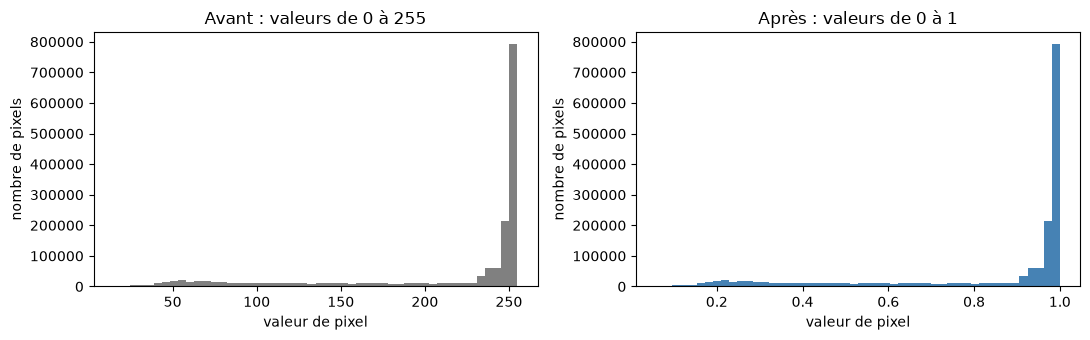

In [22]:
# 6.6 Histogrammes des valeurs : même forme de distribution, échelle différente
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(X_train_raw.ravel(), bins=50, color="gray")
axes[0].set_title("Avant : valeurs de 0 à 255")
axes[1].hist(X_train.ravel(), bins=50, color="steelblue")
axes[1].set_title("Après : valeurs de 0 à 1")
for ax in axes:
    ax.set_xlabel("valeur de pixel"); ax.set_ylabel("nombre de pixels")
plt.tight_layout()
plt.show()

In [23]:
# 6.7 Pourquoi l'échelle compte : scores d'un classifieur linéaire AVEC DES POIDS ALÉATOIRES
# (démonstration uniquement : aucun apprentissage)
def softmax(z):
    z = z - np.max(z)                  # astuce de stabilité numérique
    e = np.exp(z)
    return e / e.sum()

rng_w = np.random.default_rng(SEED)
W = rng_w.normal(0, 0.01, size=(3, 3072))   # 3 classes x 3072 caractéristiques

x_brut = X_train_raw[0].reshape(-1).astype("float32")   # valeurs 0..255
x_norm = X_train[0].reshape(-1)                         # valeurs 0..1

scores_brut = W @ x_brut
scores_norm = W @ x_norm

print("Scores avec pixels bruts      :", np.round(scores_brut, 2))
print("Probabilités (softmax)         :", np.round(softmax(scores_brut), 4))
print("\nScores avec pixels normalisés :", np.round(scores_norm, 2))
print("Probabilités (softmax)         :", np.round(softmax(scores_norm), 4))

Scores avec pixels bruts      : [-110.57   64.01  -14.37]
Probabilités (softmax)         : [0. 1. 0.]

Scores avec pixels normalisés : [-0.43  0.25 -0.06]
Probabilités (softmax)         : [0.2252 0.4465 0.3283]


### 🔍 Interprétation
- La normalisation transforme les entiers `[0, 255]` en flottants `[0, 1]` **sans changer la forme**.
- Avec les mêmes poids aléatoires, les pixels bruts produisent des scores environ **255 fois plus grands** : la probabilité devient presque `[1, 0, 0]` (ou similaire), c'est-à-dire un modèle « sûr de lui » sans raison. Avec les pixels normalisés, les scores restent modérés et l'apprentissage peut démarrer sainement.
- Remarque : on normalise avec une **constante fixe (255)**, qui ne dépend d'aucune statistique des données. Il n'y a donc pas de risque de fuite d'information du Test vers le Train. (Ce serait différent avec une standardisation par la moyenne et l'écart-type, qu'il faudrait calculer uniquement sur le Train.)

---
# Partie 7 : Préparer les entrées des trois modèles

## 7.1 Ce que chaque modèle recevra

| Modèle | Entrées | Labels |
|---|---|---|
| **k-NN** | `X_train_flat`, `X_val_flat`, `X_test_flat` | entiers |
| **Softmax** | les mêmes vecteurs aplatis | entiers (ou One-Hot si on code la perte à la main) |
| **CNN** | `X_train`, `X_val`, `X_test` en `(N, 32, 32, 3)` | entiers ou One-Hot |

Les trois modèles utilisent **exactement les mêmes images** dans **les mêmes partitions** : seule la **forme** change.

In [24]:
# 7.2 Entrées pour k-NN et Softmax : vecteurs aplatis (N, 3072)
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

# 7.3 Entrées pour le CNN : on conserve X_train, X_val, X_test en (N, 32, 32, 3) – rien à faire.

# 7.4 Labels : entiers (y_train, y_val, y_test) et One-Hot (déjà créés en Partie 5)

print("Variables prêtes :")
print("  k-NN / Softmax :", X_train_flat.shape, X_val_flat.shape, X_test_flat.shape)
print("  CNN            :", X_train.shape, X_val.shape, X_test.shape)
print("  Labels entiers :", y_train.shape, y_val.shape, y_test.shape)
print("  Labels One-Hot :", y_train_oh.shape, y_val_oh.shape, y_test_oh.shape)

Variables prêtes :
  k-NN / Softmax : (540, 3072) (180, 3072) (180, 3072)
  CNN            : (540, 32, 32, 3) (180, 32, 32, 3) (180, 32, 32, 3)
  Labels entiers : (540,) (180,) (180,)
  Labels One-Hot : (540, 3) (180, 3) (180, 3)


In [25]:
# 7.5 Résumé sous forme de tableau
resume = [
    ("X_train_flat", X_train_flat, "k-NN, Softmax"),
    ("X_val_flat",   X_val_flat,   "k-NN, Softmax"),
    ("X_test_flat",  X_test_flat,  "k-NN, Softmax"),
    ("X_train",      X_train,      "CNN"),
    ("X_val",        X_val,        "CNN"),
    ("X_test",       X_test,       "CNN"),
    ("y_train",      y_train,      "tous (entiers)"),
    ("y_val",        y_val,        "tous (entiers)"),
    ("y_test",       y_test,       "tous (entiers)"),
    ("y_train_oh",   y_train_oh,   "Softmax/CNN (One-Hot)"),
    ("y_val_oh",     y_val_oh,     "Softmax/CNN (One-Hot)"),
    ("y_test_oh",    y_test_oh,    "Softmax/CNN (One-Hot)"),
]
print(f"{'Variable':14s}{'Forme':18s}{'Type':10s}Utilisée par")
print("-" * 62)
for nom, var, usage in resume:
    print(f"{nom:14s}{str(var.shape):18s}{str(var.dtype):10s}{usage}")

Variable      Forme             Type      Utilisée par
--------------------------------------------------------------
X_train_flat  (540, 3072)       float32   k-NN, Softmax
X_val_flat    (180, 3072)       float32   k-NN, Softmax
X_test_flat   (180, 3072)       float32   k-NN, Softmax
X_train       (540, 32, 32, 3)  float32   CNN
X_val         (180, 32, 32, 3)  float32   CNN
X_test        (180, 32, 32, 3)  float32   CNN
y_train       (540,)            int64     tous (entiers)
y_val         (180,)            int64     tous (entiers)
y_test        (180,)            int64     tous (entiers)
y_train_oh    (540, 3)          float64   Softmax/CNN (One-Hot)
y_val_oh      (180, 3)          float64   Softmax/CNN (One-Hot)
y_test_oh     (180, 3)          float64   Softmax/CNN (One-Hot)


---
# Partie 8 : Vérifications

Avant de passer aux modèles, on vérifie **systématiquement** que tout est cohérent. C'est une excellente habitude : la plupart des erreurs en ML viennent de dimensions ou de partitions incorrectes.

In [26]:
# 8.1 Dimensions et nombre d'images
assert X_train.shape == (540, 32, 32, 3) and X_val.shape == (180, 32, 32, 3) and X_test.shape == (180, 32, 32, 3)
assert X_train_flat.shape == (540, 3072) and X_val_flat.shape == (180, 3072) and X_test_flat.shape == (180, 3072)
assert y_train.shape == (540,) and y_val.shape == (180,) and y_test.shape == (180,)
assert y_train_oh.shape == (540, 3) and y_val_oh.shape == (180, 3) and y_test_oh.shape == (180, 3)

total = len(X_train) + len(X_val) + len(X_test)
print("Total d'images :", total, "(attendu : 900)")
assert total == 900
print("Proportions : Train {:.0%} | Val {:.0%} | Test {:.0%}".format(
    len(X_train) / total, len(X_val) / total, len(X_test) / total))

# 8.2 Valeurs minimales et maximales
for nom, X in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test),
               ("X_train_flat", X_train_flat), ("X_val_flat", X_val_flat), ("X_test_flat", X_test_flat)]:
    print(f"{nom:13s} min = {X.min():.3f} | max = {X.max():.3f}")
    assert X.min() >= 0.0 and X.max() <= 1.0

# 8.3 Labels
for nom, y in [("y_train", y_train), ("y_val", y_val), ("y_test", y_test)]:
    print(f"{nom:8s} valeurs possibles : {np.unique(y)} | par classe : {np.bincount(y)}")
    assert set(np.unique(y)) == {0, 1, 2}

Total d'images : 900 (attendu : 900)
Proportions : Train 60% | Val 20% | Test 20%
X_train       min = 0.059 | max = 1.000
X_val         min = 0.063 | max = 1.000
X_test        min = 0.063 | max = 1.000
X_train_flat  min = 0.059 | max = 1.000
X_val_flat    min = 0.063 | max = 1.000
X_test_flat   min = 0.063 | max = 1.000
y_train  valeurs possibles : [0 1 2] | par classe : [180 180 180]
y_val    valeurs possibles : [0 1 2] | par classe : [60 60 60]
y_test   valeurs possibles : [0 1 2] | par classe : [60 60 60]


In [27]:
# 8.4 Cohérence des représentations
# a) Le flattening conserve les valeurs : on retrouve exactement les images 4D
assert np.array_equal(X_train_flat.reshape(-1, 32, 32, 3), X_train)
assert np.array_equal(X_val_flat.reshape(-1, 32, 32, 3), X_val)
assert np.array_equal(X_test_flat.reshape(-1, 32, 32, 3), X_test)

# b) Une ligne de X_flat correspond bien à l'image du même index
i = 123
assert np.array_equal(X_train_flat[i], X_train[i].reshape(-1))

# c) Le One-Hot est cohérent avec les labels entiers
assert np.array_equal(np.argmax(y_train_oh, axis=1), y_train)
assert np.array_equal(np.argmax(y_val_oh, axis=1), y_val)
assert np.array_equal(np.argmax(y_test_oh, axis=1), y_test)
assert np.all(y_train_oh.sum(axis=1) == 1)

# d) Les partitions sont disjointes (aucune image dans deux ensembles) et couvrent les 900 images
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val) & set(idx_test)) == 0
assert len(set(idx_train) | set(idx_val) | set(idx_test)) == 900

# e) Stratification : mêmes effectifs par classe dans chaque ensemble
assert np.all(np.bincount(y_train) == 180)
assert np.all(np.bincount(y_val) == 60)
assert np.all(np.bincount(y_test) == 60)

# f) Les trois modèles partagent les mêmes images : le nombre de lignes est identique
assert X_train_flat.shape[0] == X_train.shape[0] == y_train.shape[0] == y_train_oh.shape[0]

print("✅ Toutes les vérifications sont passées : les représentations sont cohérentes.")

✅ Toutes les vérifications sont passées : les représentations sont cohérentes.


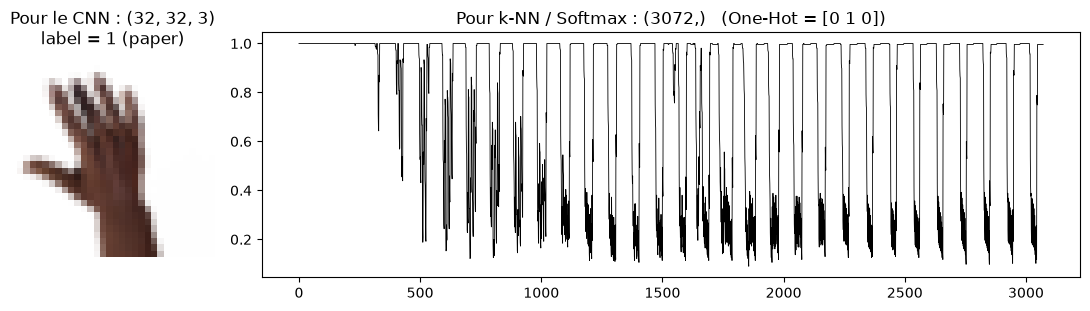

In [28]:
# 8.5 Contrôle visuel : la même image dans les deux représentations, avec son label
i = 10
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 4]})
axes[0].imshow(X_train[i]); axes[0].axis("off")
axes[0].set_title(f"Pour le CNN : {X_train[i].shape}\nlabel = {y_train[i]} ({class_names[y_train[i]]})")
axes[1].plot(X_train_flat[i], linewidth=0.6, color="black")
axes[1].set_title(f"Pour k-NN / Softmax : {X_train_flat[i].shape}   (One-Hot = {y_train_oh[i].astype(int)})")
plt.tight_layout()
plt.show()

### ✅ Bilan
Les données sont prêtes :
- **k-NN et Softmax** → `X_*_flat` de forme `(N, 3072)` ;
- **CNN** → `X_*` de forme `(N, 32, 32, 3)` ;
- **Labels** → entiers et One-Hot, avec les mêmes partitions pour les trois modèles ;
- **Valeurs** → normalisées dans `[0, 1]`.

Le prochain notebook pourra donc se concentrer sur l'entraînement et l'évaluation.

---
# Partie 9 : Questions de compréhension

📝 Réponds d'abord **par écrit, de mémoire**, avant de consulter la correction tout en bas du notebook (qui est volontairement repliée).

### Niveau 1 – Les bases
**Q1.** Quelle est la forme d'une image RGB 32 × 32 ? Que représente chacun de ses trois nombres ? Combien de valeurs contient-elle ?

**Q2.** Quelle est la différence entre la forme `(32, 32, 3)` et la forme `(540, 32, 32, 3)` ?

### Niveau 2 – Le Flattening
**Q3.** Que fait l'instruction `X_train.reshape(X_train.shape[0], -1)` ? Que signifie le `-1` ? Quelle forme obtient-on ?

**Q4.** Après le Flattening, a-t-on « perdu » des informations ? Distingue la perte des valeurs des pixels et la perte de la structure spatiale explicite.

**Q5.** Pourquoi k-NN et Softmax peuvent-ils fonctionner sur des vecteurs aplatis ? (Aide : repense à l'expérience où nous avons mélangé les colonnes.)

### Niveau 3 – CNN, labels, normalisation
**Q6.** Pourquoi le CNN conserve-t-il la forme `(32, 32, 3)` ? Quel rôle joue le voisinage des pixels dans une convolution ?

**Q7.** Quelle est la différence entre un label entier et un label One-Hot ? Quelle fonction de perte Keras associer à chaque format ?

**Q8.** Pourquoi divise-t-on les pixels par 255 ? Cette opération modifie-t-elle la forme des données ? En quoi diffère-t-elle du Flattening ?

### Niveau 4 – Réflexion
**Q9.** On te propose d'utiliser des partitions différentes pour k-NN et pour le CNN « pour que chaque modèle ait de meilleures chances ». Pourquoi est-ce une mauvaise idée pour une **comparaison** ?

**Q10.** Un camarade calcule la moyenne et l'écart-type sur **tout** le dataset (Train + Val + Test) pour standardiser les pixels. Quel problème cela pose-t-il ? Pourquoi la division par 255 ne pose-t-elle pas ce problème ?

> ⏸️ **STOP** – Écris tes réponses avant de descendre à la correction.

---
# 🔒 Correction des questions de compréhension

*(Cliquez sur chaque flèche pour afficher la réponse. Ne les ouvre qu'après avoir répondu.)*

<details><summary><b>Q1</b></summary>

La forme est `(32, 32, 3)` : 32 lignes, 32 colonnes, 3 canaux. Les 3 nombres d'un pixel sont ses intensités en **rouge, vert et bleu** (de 0 à 255 en brut, de 0 à 1 une fois normalisées). Une image contient 32 × 32 × 3 = **3 072 valeurs**.
</details>

<details><summary><b>Q2</b></summary>

`(32, 32, 3)` est **une seule image**. `(540, 32, 32, 3)` est un **ensemble de 540 images** : on a ajouté un premier axe qui indexe les images.
</details>

<details><summary><b>Q3</b></summary>

Elle conserve le premier axe (540 images) et **aplatit tout le reste** en une seule dimension. Le `-1` demande à NumPy de calculer automatiquement la taille manquante (32 × 32 × 3 = 3072). On obtient `(540, 3072)` : une ligne par image.
</details>

<details><summary><b>Q4</b></summary>

Les **valeurs** des pixels ne sont **pas perdues** : le `reshape` inverse redonne exactement l'image (`np.array_equal` → `True`). Ce qui n'est plus explicite, c'est la **structure spatiale** : le voisinage 2D (haut/bas/gauche/droite) n'apparaît plus dans le vecteur (deux voisins verticaux sont séparés de 96 positions). L'information existe encore implicitement dans l'ordre, mais le modèle ne l'exploite pas.
</details>

<details><summary><b>Q5</b></summary>

k-NN compare des images par une **distance** calculée valeur par valeur ; Softmax calcule `W · x + b` avec un poids par valeur. Aucun des deux n'utilise la notion de voisinage. Preuve : si on permute les colonnes de la même façon pour toutes les images, les distances (donc les voisins de k-NN) ne changent pas. Ils ont donc besoin d'un vecteur de caractéristiques `(3072,)`, pas d'une grille 2D.
</details>

<details><summary><b>Q6</b></summary>

Le CNN s'appuie sur des **filtres locaux** (par exemple 3×3) qui glissent sur l'image et détectent des motifs formés par des pixels **voisins** (contours, coins, formes de doigts). Il faut donc conserver la grille 2D pour que « voisin » ait un sens. En plus, un même filtre est réutilisé partout (partage de poids), ce qui réduit fortement le nombre de paramètres.
</details>

<details><summary><b>Q7</b></summary>

Un label **entier** est le numéro de classe (ex. `1` pour paper), forme `(N,)`. Un label **One-Hot** est un vecteur avec un seul 1 (ex. `[0, 1, 0]`), forme `(N, 3)`. Entiers → `sparse_categorical_crossentropy` ; One-Hot → `categorical_crossentropy`. La valeur de la perte est la même, seul le format change.
</details>

<details><summary><b>Q8</b></summary>

255 est la valeur maximale d'un pixel (8 bits) : diviser par 255 ramène les valeurs dans [0, 1]. Cela évite des scores trop grands (saturation du Softmax) et stabilise l'apprentissage. La **forme ne change pas** : on modifie les **valeurs** (échelle). Le Flattening modifie la **forme** mais pas les valeurs.
</details>

<details><summary><b>Q9</b></summary>

Pour comparer des modèles, il faut les évaluer **dans les mêmes conditions** : mêmes images d'entraînement, de validation et de test. Si les partitions diffèrent, une différence de performance peut venir de la chance du découpage plutôt que de la qualité du modèle. De plus, des partitions choisies « en fonction du modèle » introduiraient un biais.
</details>

<details><summary><b>Q10</b></summary>

Calculer des statistiques sur Train + Val + Test fait **fuiter de l'information du Test vers l'entraînement** (*data leakage*) : les performances mesurées deviennent trop optimistes. Les statistiques doivent être calculées **uniquement sur le Train**, puis appliquées à Val et Test. La division par 255 utilise une constante fixe, indépendante des données : aucune fuite possible.
</details>

---
🎉 **Fin du Notebook 2.** Les données sont prêtes pour l'entraînement de k-NN, du classifieur Softmax et du CNN (Notebook 3).

In [34]:
np.savez_compressed("../data/rps_32x32_split.npz",
                    X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test,
                    class_names=np.array(class_names))